# Insurance Behavior Lab — EDA sampai model

Data **sintetis**, bukan fakta bisnis. Jalankan sel berurutan. Notebook memanggil modul yang sama
dengan pipeline CLI sehingga preprocessing dan evaluasi tetap konsisten.
Sasaran: memahami tiga misteri bisnis, membangun prediksi, dan merancang eksperimen.
Output notebook disimpan di `artifacts/notebook_run/` agar hasil utama tetap mudah dibandingkan.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'insurance_lab').exists():
    ROOT = ROOT.parent
assert (ROOT / 'insurance_lab').exists(), 'Buka notebook dari folder proyek atau notebooks/'
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from insurance_lab.config import TARGET, FEATURES, split_months
from insurance_lab.data import (simulate_policies, engineer_policy_features,
    simulate_acquisition, engineer_acquisition_features, audit_policy_data)
from insurance_lab.modeling import train_churn, train_acquisition
OUT = ROOT / 'artifacts/notebook_run'
for folder in ['artifacts/tables', 'artifacts/models', 'data/processed', 'reports/figures']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
SEED = 26


## 1. Rumuskan masalah sebelum melihat model

Tulis dua hipotesis untuk setiap fenomena: premi naik tanpa churn langsung, churn melonjak
beberapa waktu kemudian, dan akuisisi meningkat di luar campaign.
Definisikan unit, horizon, outcome dan data tambahan yang diperlukan.
Jangan membuka formula simulator sebelum latihan hipotesis selesai.


In [2]:
raw = simulate_policies(n_customers=6000, seed=SEED)
df = engineer_policy_features(raw)
audit = audit_policy_data(df)
display(pd.Series({k: v for k, v in audit.items() if k != 'missing_by_column'}))
display(df.head())


rows                136276.000000
customers             6000.000000
months                  45.000000
duplicate_keys           0.000000
churn_prevalence         0.029536
dtype: float64

,customer_id,snapshot_date,feature_as_of,label_end_date,entry_date,is_inception_cohort,age,region,product,income_band,...,economic_stress_index,months_to_renewal,late_payments_3m,complaints_3m,claims_3m,days_since_contact,app_sessions_1m,churn_next_month,premium_to_income,renewal_payment_interaction
0,1,2023-01-01,2022-12-31,2023-02-01,2023-01-01,False,58,Jabodetabek,Kesehatan,Low,...,0.24,11,0,0,0,37,5.0,0,0.219737,0
1,2,2023-01-01,2022-12-31,2023-02-01,2023-01-01,False,48,Jawa_lain,Jiwa,Mid,...,0.24,8,0,0,0,106,7.0,0,0.060824,0
2,3,2023-01-01,2022-12-31,2023-02-01,2023-01-01,False,36,Sumatera,Kendaraan,Low,...,0.24,0,0,0,0,128,1.0,0,0.131842,0
3,6,2023-01-01,2022-12-31,2023-02-01,2023-01-01,False,26,Jawa_lain,Kesehatan,High,...,0.24,1,0,0,0,115,6.0,0,0.013263,0
4,8,2023-01-01,2022-12-31,2023-02-01,2023-01-01,False,36,Jawa_lain,Kesehatan,Mid,...,0.24,3,0,0,0,34,9.0,0,0.084235,0


## 2. Audit data dan waktu

Apa arti `feature_as_of`, `snapshot_date`, dan `label_end_date`?
Mengapa satu nasabah muncul berulang? Bolehkah ia muncul sesudah terminal churn?
Missingness diisi **di dalam pipeline yang fit pada train**, bukan di seluruh DataFrame.


In [3]:
display(df.isna().mean().sort_values(ascending=False).head(8))
display(df[FEATURES].describe(include='all').T)
assert (df.feature_as_of < df.snapshot_date).all()
assert (df.label_end_date > df.snapshot_date).all()


app_sessions_1m       0.012056
region                0.006098
customer_id           0.000000
premium_change_pct    0.000000
premium_to_income     0.000000
churn_next_month      0.000000
days_since_contact    0.000000
claims_3m             0.000000
dtype: float64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,136276.0,NaN,NaN,NaN,43.464205,12.675474,22.0,33.0,43.0,55.0,65.0
tenure_months,136276.0,NaN,NaN,NaN,33.108324,21.470884,0.0,15.0,32.0,49.0,92.0
premium_idr,136276.0,NaN,NaN,NaN,536395.162024,203407.402163,180000.0,358000.0,539000.0,710600.0,933900.0
premium_change_pct,136276.0,NaN,NaN,NaN,0.040622,0.049113,0.0,0.0,0.0,0.1,0.1
economic_stress_index,136276.0,NaN,NaN,NaN,0.30476,0.163095,0.17,0.2044,0.2667,0.3057,0.7776
months_to_renewal,136276.0,NaN,NaN,NaN,5.544292,3.483392,0.0,3.0,6.0,9.0,11.0
late_payments_3m,136276.0,NaN,NaN,NaN,0.499017,0.67312,0.0,0.0,0.0,1.0,3.0
complaints_3m,136276.0,NaN,NaN,NaN,0.138286,0.370802,0.0,0.0,0.0,0.0,3.0
claims_3m,136276.0,NaN,NaN,NaN,0.260523,0.496472,0.0,0.0,0.0,0.0,3.0
days_since_contact,136276.0,NaN,NaN,NaN,109.485794,94.272459,1.0,35.0,82.0,160.0,365.0


## 3. EDA: rate, denominator, segmen dan cohort

Bandingkan churn rate dan jumlah churn. Apakah perubahan jumlah pelanggan aktif mengubah
interpretasi? Hipotesis mana yang sesuai dengan pola renewal dan riwayat pembayaran?


,active,churned,churn_rate
snapshot_date,,,
2025-10-01,2626,67,0.025514
2025-11-01,2606,65,0.024942
2025-12-01,2588,67,0.025889
2026-01-01,2577,64,0.024835
2026-02-01,2570,67,0.026070
2026-03-01,2578,44,0.017067
2026-04-01,2534,109,0.043015
2026-05-01,2425,149,0.061443
2026-06-01,2276,153,0.067223


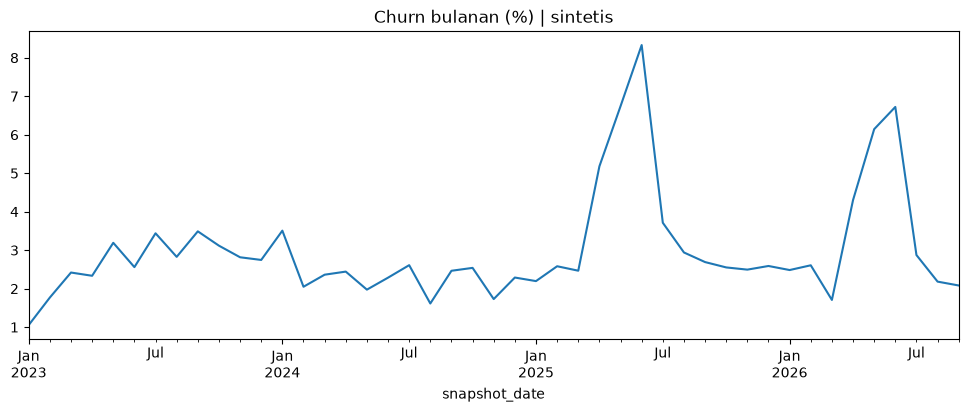

In [4]:
monthly = df.groupby('snapshot_date').agg(
    active=(TARGET, 'size'), churned=(TARGET, 'sum'), churn_rate=(TARGET, 'mean'))
display(monthly.tail(12))
monthly.churn_rate.mul(100).plot(figsize=(12, 4), title='Churn bulanan (%) | sintetis');


In [5]:
segment = df.assign(near_renewal=df.months_to_renewal.le(1),
                    payment_issue=df.late_payments_3m.gt(0))
display(segment.groupby(['near_renewal', 'payment_issue'])[TARGET].agg(['size', 'mean']))


size      mean
near_renewal payment_issue                 
False        False          66508  0.011502
             True           46662  0.036304
True         False          14534  0.023737
             True            8572  0.142441

## 4. Fitur dan pemisahan waktu

Horizon adalah satu bulan kalender. Jul 2025 dan Jan 2026 adalah embargo.
Nasabah yang sama dapat berada di beberapa split pada waktu berbeda: ini meniru scoring
portofolio. Generalisasi ke nasabah yang benar-benar baru memerlukan evaluasi tambahan.


In [6]:
splits = split_months(df)
display(pd.DataFrame([{'split': name, 'rows': len(part),
    'start': part.snapshot_date.min(), 'end': part.snapshot_date.max(),
    'prevalence': part[TARGET].mean()} for name, part in splits.items()]))
assert splits['train'].label_end_date.max() < splits['validation'].snapshot_date.min()
assert splits['validation'].label_end_date.max() < splits['test'].snapshot_date.min()
display(df[['premium_idr', 'income_monthly_idr', 'premium_to_income',
            'months_to_renewal', 'late_payments_3m', 'renewal_payment_interaction']].head())


,split,rows,start,end,prevalence
0,train,99308,2023-01-01,2025-06-01,0.028628
1,validation,13112,2025-08-01,2025-12-01,0.026541
2,test,18585,2026-02-01,2026-09-01,0.036051


,premium_idr,income_monthly_idr,premium_to_income,months_to_renewal,late_payments_3m,renewal_payment_interaction
0,835000,3800000,0.219737,11,0,0
1,517000,8500000,0.060824,8,0,0
2,501000,3800000,0.131842,0,0,0
3,252000,19000000,0.013263,1,0,0
4,716000,8500000,0.084235,3,0,0


## 5. Baseline dan model churn

Sel ini menjalankan tiga rolling backtest, fit train, pemilihan AP validation, final test,
permutation importance validation dan bootstrap customer. Model tidak dipilih dari test.
Perhatikan bahwa `average_precision` bukan trapezoidal PR-AUC.


In [7]:
churn = train_churn(df, OUT, SEED)
print('Model terpilih:', churn['selected_model'])
display(churn['metrics'].round(4))
display(pd.read_csv(OUT / 'artifacts/tables/rolling_backtest.csv').round(4))


Model terpilih: logistic_regression


,model,split,rows,positives,prevalence,roc_auc,average_precision,brier,precision_at_10pct,recall_at_10pct,lift_at_10pct,selected_on_validation
0,prevalence_baseline,validation,13112,348,0.0265,0.5000,0.0265,0.0258,0.0198,0.0747,0.7461,False
1,prevalence_baseline,test,18585,670,0.0361,0.5000,0.0361,0.0348,0.0349,0.0970,0.9683,False
2,logistic_regression,validation,13112,348,0.0265,0.7481,0.1257,0.0247,0.1081,0.4080,4.0749,True
3,logistic_regression,test,18585,670,0.0361,0.7823,0.1936,0.0319,0.1407,0.3910,3.9031,True
4,hist_gradient_boosting,validation,13112,348,0.0265,0.7510,0.1230,0.0247,0.1059,0.3994,3.9888,False
5,hist_gradient_boosting,test,18585,670,0.0361,0.7796,0.1887,0.0319,0.1364,0.3791,3.7839,False


,fold,model,train_end,validation_start,validation_end,rows,positives,prevalence,roc_auc,average_precision,brier,precision_at_10pct,recall_at_10pct,lift_at_10pct
0,1,prevalence_baseline,2024-06-01,2024-08-01,2024-10-01,9475,209,0.0221,0.5000,0.0221,0.0216,0.0190,0.0861,0.8608
1,1,logistic_regression,2024-06-01,2024-08-01,2024-10-01,9475,209,0.0221,0.7568,0.1335,0.0203,0.0939,0.4258,4.2561
2,1,hist_gradient_boosting,2024-06-01,2024-08-01,2024-10-01,9475,209,0.0221,0.7518,0.1348,0.0204,0.0886,0.4019,4.0170
3,2,prevalence_baseline,2024-09-01,2024-11-01,2025-01-01,9411,195,0.0207,0.5000,0.0207,0.0203,0.0233,0.1128,1.1259
4,2,logistic_regression,2024-09-01,2024-11-01,2025-01-01,9411,195,0.0207,0.7800,0.1666,0.0187,0.1060,0.5128,5.1179
5,2,hist_gradient_boosting,2024-09-01,2024-11-01,2025-01-01,9411,195,0.0207,0.7861,0.1691,0.0187,0.1050,0.5077,5.0667
6,3,prevalence_baseline,2024-12-01,2025-02-01,2025-04-01,9368,319,0.0341,0.5000,0.0341,0.0330,0.0341,0.1003,1.0019
7,3,logistic_regression,2024-12-01,2025-02-01,2025-04-01,9368,319,0.0341,0.7738,0.1907,0.0303,0.1311,0.3856,3.8509
8,3,hist_gradient_boosting,2024-12-01,2025-02-01,2025-04-01,9368,319,0.0341,0.7656,0.1836,0.0306,0.1343,0.3950,3.9448


## 6. Error analysis dan kalibrasi

Top 10% dipilih per bulan. Confusion matrix memakai threshold tetap validation.
Mengapa hasil kedua aturan berbeda? Reliability diagram bersifat diagnostik;
recalibration belum diterapkan. Brier yang kecil saja belum menjamin kalibrasi baik.


,feature,ap_drop_mean,ap_drop_std
12,renewal_payment_interaction,0.071194,0.004830
6,late_payments_3m,0.033652,0.009462
9,days_since_contact,0.019726,0.003007
11,premium_to_income,0.011702,0.004099
5,months_to_renewal,0.008649,0.005823
15,income_band,0.008631,0.012968
2,premium_idr,0.008508,0.002177
7,complaints_3m,0.006832,0.003025
10,app_sessions_1m,0.004666,0.003670
13,region,0.001344,0.001196


,customer_id,snapshot_date,region,income_band,churn_next_month,score,above_validation_threshold,selected_top10_month,premium_idr,months_to_renewal,late_payments_3m,complaints_3m,assumed_retained_margin_idr,scenario_net_value_idr,suggested_review
117701,18,2026-02-01,Jabodetabek,Low,0,0.059329,True,True,267300,10,1,1,641520.0,-7387.805478,Tinjau keluhan layanan
117719,51,2026-02-01,Jawa_lain,Low,0,0.078600,True,True,484000,1,1,0,1161600.0,3260.267974,Tawarkan bantuan pembayaran
117726,71,2026-02-01,Jabodetabek,Low,0,0.072786,True,True,541200,0,1,0,1298880.0,3908.169711,Tawarkan bantuan pembayaran


,customer_id,snapshot_date,region,income_band,churn_next_month,score,above_validation_threshold,selected_top10_month,premium_idr,months_to_renewal,late_payments_3m,complaints_3m,assumed_retained_margin_idr,scenario_net_value_idr,suggested_review
117730,78,2026-02-01,Jawa_lain,Mid,1,0.037452,False,False,215600,8,1,0,517440.0,-11124.169260,Tawarkan bantuan pembayaran
117871,406,2026-02-01,Jawa_lain,High,1,0.006386,False,False,327800,6,0,0,786720.0,-13995.180010,Tinjau kebutuhan proteksi
117894,462,2026-02-01,Jawa_lain,Low,1,0.047655,False,True,927300,0,0,0,2225520.0,6211.378672,Pengingat renewal


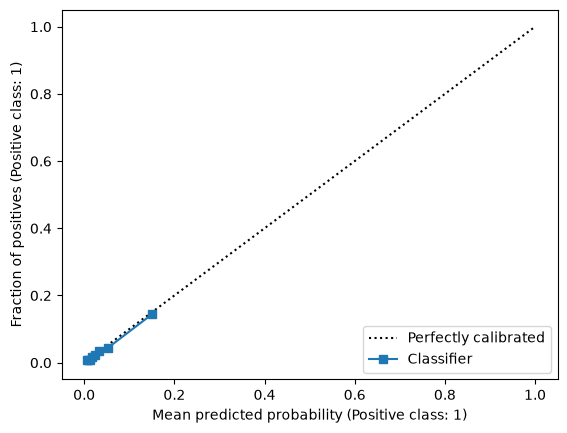

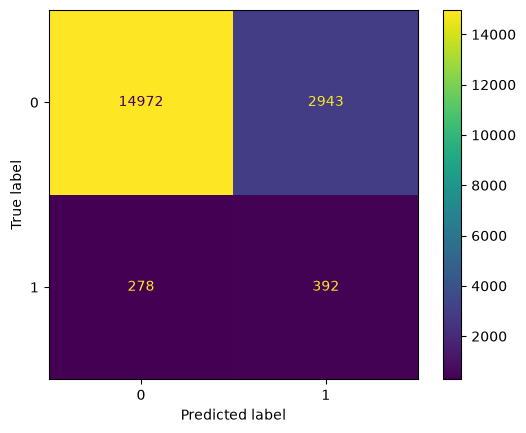

In [8]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay
scored = churn['scored']
CalibrationDisplay.from_predictions(scored[TARGET], scored.score, n_bins=8, strategy='quantile');
ConfusionMatrixDisplay(churn['confusion']).plot();
display(churn['importance'].head(10))
display(scored.loc[scored.above_validation_threshold & scored[TARGET].eq(0)].head(3))
display(scored.loc[~scored.above_validation_threshold & scored[TARGET].eq(1)].head(3))


## 7. Akuisisi mingguan: jalur yang berbeda

Dataset akuisisi ini simulasi analitis terpisah dari daftar nasabah.
Lag hanya memakai minggu yang sudah terjadi. Semua wilayah dalam minggu sama masuk
split yang sama. Ini prediksi satu minggu ke depan pada setiap origin, bukan multi-step.


In [9]:
acquisition_raw = simulate_acquisition(SEED)
acquisition_features = engineer_acquisition_features(acquisition_raw)
acquisition = train_acquisition(acquisition_features, OUT)
display(acquisition['metrics'].round(3))
display(acquisition['scored'].loc[acquisition['scored'].unusual_residual].head())


,model,split,region_week_mae,weekly_total_mae,weekly_total_wape,poisson_deviance,selected_on_validation
0,lag1_naive,validation,6.882,19.318,0.135,2.953,False
1,poisson_regression,validation,3.846,9.660,0.068,0.844,True
2,lag1_naive,test,6.947,22.853,0.161,2.954,False
3,poisson_regression,test,4.001,10.819,0.076,0.938,True


,week,region,new_policies,prediction,residual,unusual_residual
157,2026-02-02,Indonesia_timur,11,20.515284,-9.515284,True
170,2026-05-04,Indonesia_timur,32,21.029051,10.970949,True
363,2026-05-18,Jabodetabek,50,38.644174,11.355826,True
364,2026-05-25,Jabodetabek,41,28.905121,12.094879,True
372,2026-07-20,Jabodetabek,50,40.549204,9.450796,True


## 8. Buat seluruh visual dan baca dashboard

Periksa cohort retention: sel kosong adalah follow-up belum lengkap. Periksa grafik
sensitivitas: keuntungan bergantung pada asumsi rescue fraction yang belum diukur.


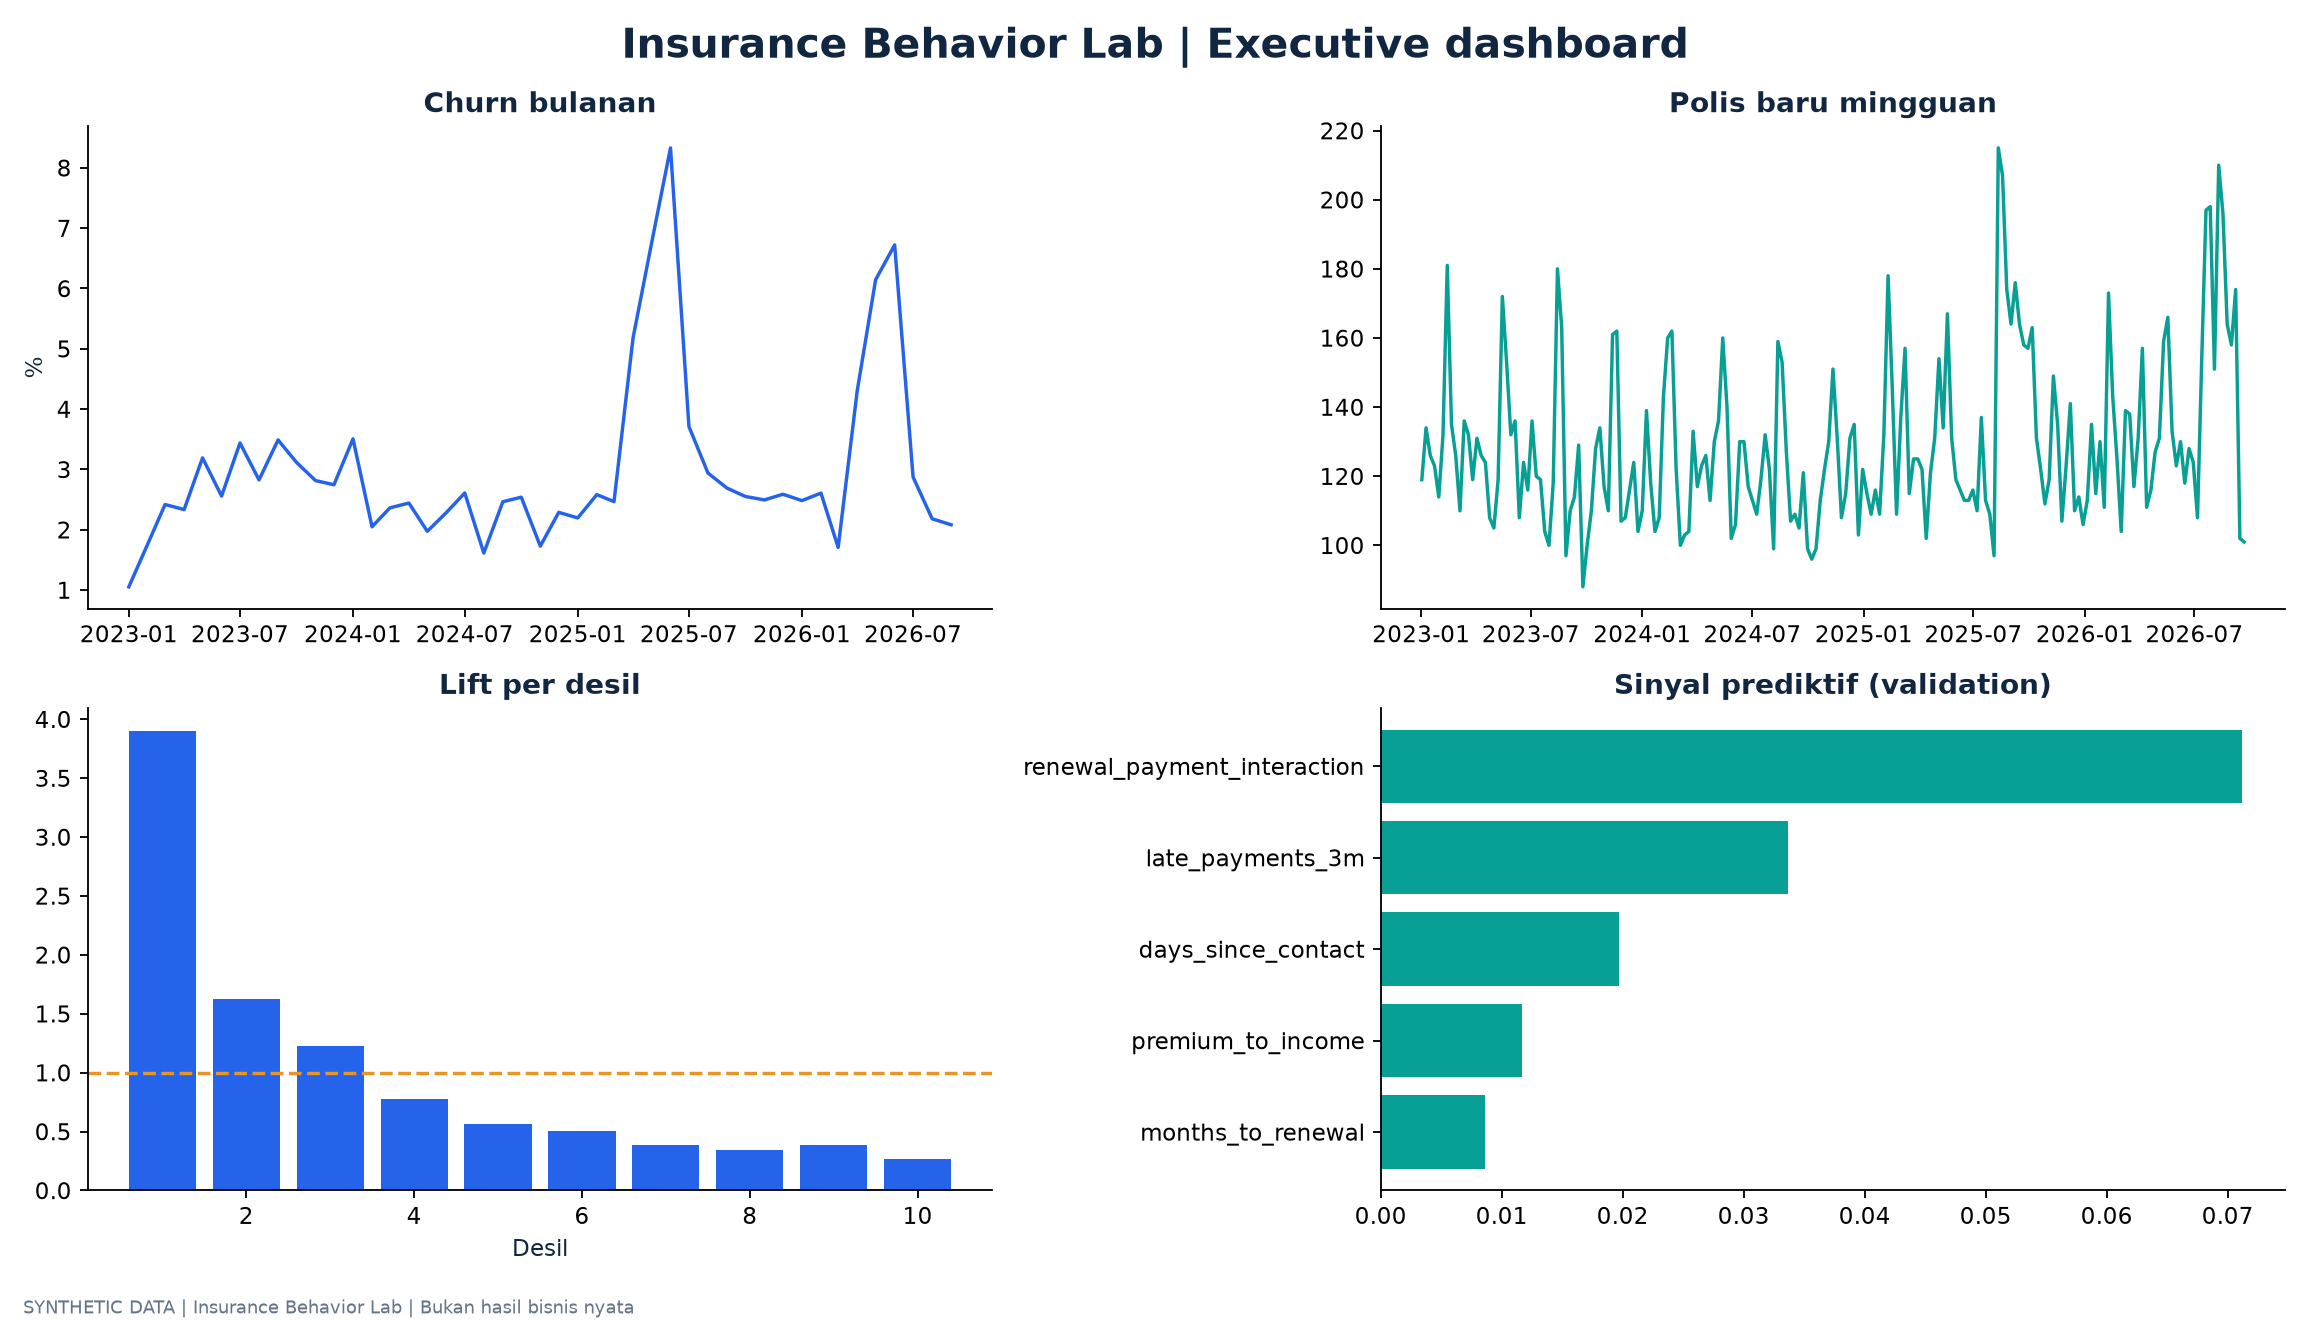

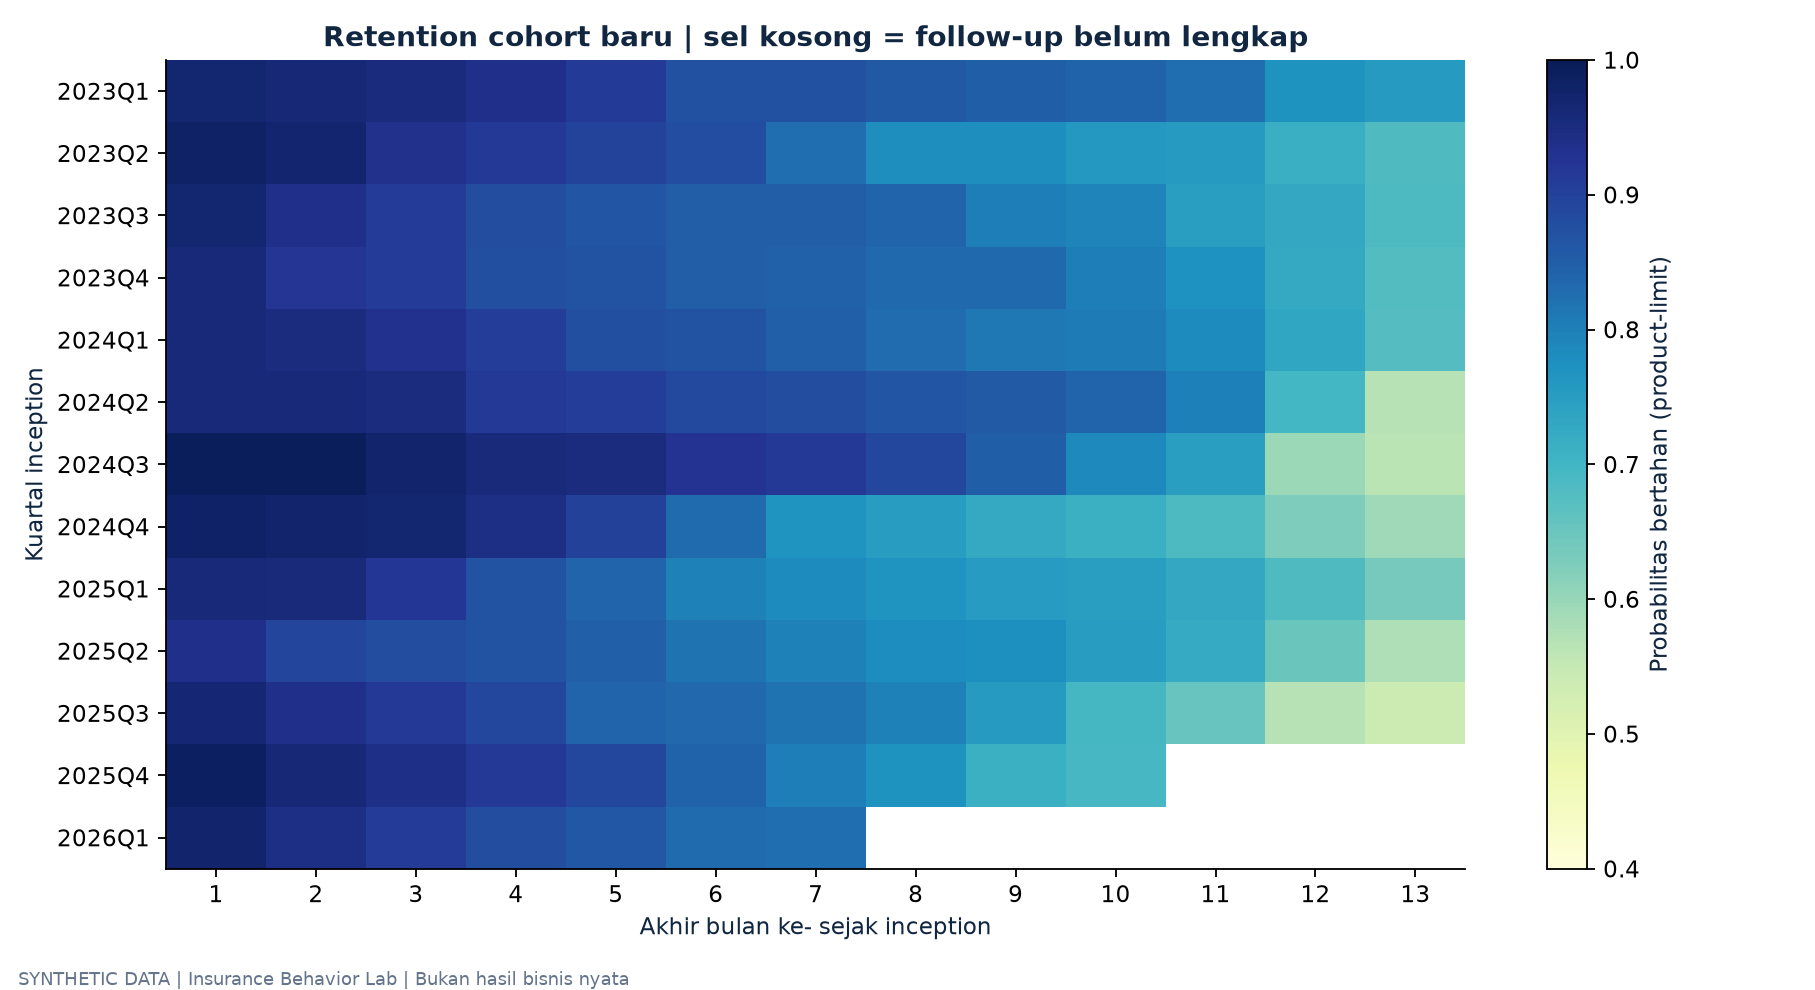

In [10]:
from insurance_lab.visuals import create_figures
monthly, figures = create_figures(df, acquisition_raw, acquisition_features,
                                 churn, acquisition, OUT)
display(Image(filename=str(OUT / 'reports/figures/executive_dashboard.png')))
display(Image(filename=str(OUT / 'reports/figures/cohort_retention.png')))


## 9. Kesimpulan dan keputusan

Isi memo empat paragraf: fakta deskriptif; kualitas prediksi; hal yang belum diketahui;
eksperimen berikutnya. Jangan menyebut importance sebagai sebab atau angka simulasi
sebagai fakta Indonesia. Bandingkan kapasitas kontak 5%, 10%, 20% dengan skenario biaya.


In [11]:
display(pd.read_csv(OUT / 'artifacts/tables/retention_sensitivity.csv'))
display(pd.DataFrame(churn['intervals']))


,capacity,assumed_rescue_fraction,contacts,precision,hypothetical_net_value_idr
0,0.05,0.05,933,0.201501,-1.183405e+05
1,0.05,0.10,933,0.201501,1.375832e+07
2,0.05,0.20,933,0.201501,4.151164e+07
3,0.05,0.30,933,0.201501,6.926496e+07
4,0.10,0.05,1862,0.140709,-7.994351e+06
5,0.10,0.10,1862,0.140709,1.194130e+07
6,0.10,0.20,1862,0.140709,5.181260e+07
7,0.10,0.30,1862,0.140709,9.168390e+07
8,0.20,0.05,3720,0.099731,-2.820240e+07
9,0.20,0.10,3720,0.099731,-6.048033e+05


,average_precision,lift_at_10pct
lower_95,0.164463,3.488506
upper_95,0.222263,4.216451


## 10. Uji inference dari artifact

Contoh ini memakai snapshot historis sintetis, bukan nasabah live. Gunakan joblib
hanya dari sumber tepercaya.


In [12]:
import joblib
bundle = joblib.load(OUT / 'artifacts/models/churn_model.joblib')
example = pd.read_csv(OUT / 'data/processed/scoring_example.csv')
example['churn_probability'] = bundle['pipeline'].predict_proba(example[bundle['features']])[:, 1]
display(example[['customer_id', 'snapshot_date', 'churn_probability']].head(10))


,customer_id,snapshot_date,churn_probability
0,4,2026-09-01,0.019578
1,6,2026-09-01,0.006322
2,7,2026-09-01,0.012282
3,8,2026-09-01,0.008503
4,9,2026-09-01,0.035840
5,10,2026-09-01,0.004419
6,12,2026-09-01,0.050418
7,16,2026-09-01,0.011679
8,20,2026-09-01,0.008485
9,22,2026-09-01,0.023443
